## IN03: API vs MCP, Framework Selection, and Build vs Buy

In [1]:
# IN03: API vs MCP, Framework Selection, and Build vs Buy

In [2]:
# Problem Statement: Walmart AI Retail Assistant — API vs MCP, Framework Selection, and Build vs Buy

In [3]:
# Imagine you are an AI engineer working for Walmart India.

# Walmart operates thousands of stores, and store managers must decide which products should be stocked based on changing customer demand.

# Consider a Walmart store in Bengaluru. -> Store WMT-2847 — Bengaluru
#     "Based on today's actual conditions, what should we prioritise stocking today?"

# Traditionally, a store manager might look at weather forecasts, search market trends, analyse demand, and then decide what to stock.
# This is time-consuming, particularly when the same process needs to be repeated across thousands of stores.

# Our objective is to build an AI Retail Assistant that performs this analysis automatically and recommends three product categories to prioritise, with supporting reasons.

# Example
# Suppose the live weather API reports heavy rainfall in Bengaluru, and market information suggests increased demand for rain-related products.

# The AI assistant might recommend:
# - Umbrellas — because rain can increase customer demand.
# - Raincoats — because customers need protection during wet weather.
# - Waterproof footwear — because rainy conditions may increase demand.
# These are illustrative recommendations, not actual API results from this notebook execution.

## How will our AI assistant solve this problem?

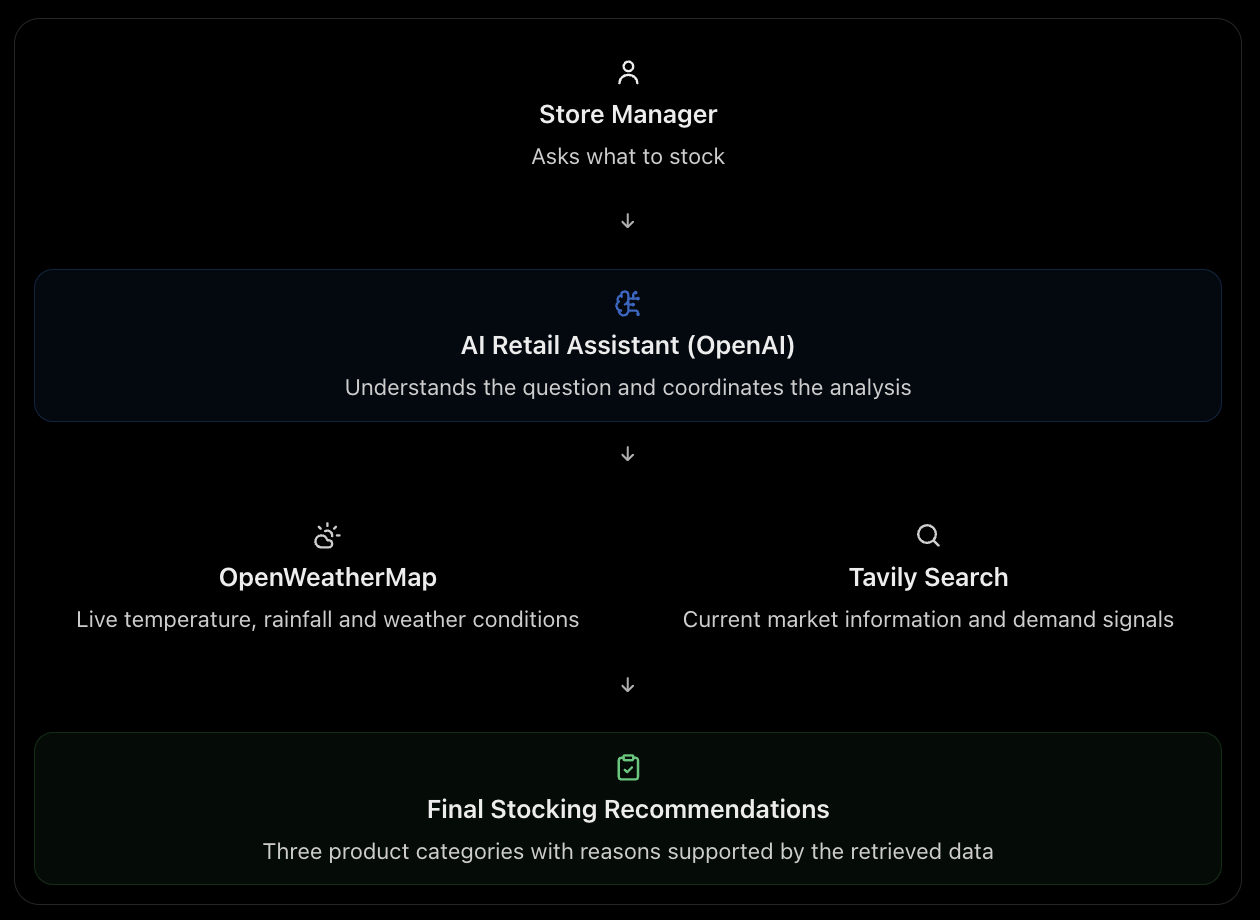

In [4]:
# What are we actually learning through this problem?
# It investigates three decisions.

# Decision 1 — REST API vs MCP
# Decision 2 — Python vs LangChain vs LangGraph
# Decision 3 — Build vs Buy

In [5]:
# Load the libraries and keys needed for the full notebook.
# This cell also defines the store we will use in every example.
import os
import json
import time
import requests
from typing import TypedDict
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(override=True)

OPENAI_KEY  = os.getenv('OPENAI_API_KEY')
WEATHER_KEY = os.getenv('OPENWEATHERMAP_API_KEY')
TAVILY_KEY  = os.getenv('TAVILY_API_KEY')

client = OpenAI(api_key=OPENAI_KEY)

# Check whether all required API keys are present before we continue.
missing = [k for k, v in {
    'OPENAI_API_KEY':         OPENAI_KEY,
    'OPENWEATHERMAP_API_KEY': WEATHER_KEY,
    'TAVILY_API_KEY':         TAVILY_KEY,
}.items() if not v]

if missing:
    print(f'WARNING: Missing API keys: {missing}')
    print('Add them to your .env file before running this notebook.')
else:
    print('All required API keys loaded.')

# Fixed store context keeps every comparison in the notebook consistent.
STORE_ID   = 'WMT-2847'
STORE_CITY = 'Bengaluru'
print(f'Store context: {STORE_ID} | {STORE_CITY}, India')

All required API keys loaded.
Store context: WMT-2847 | Bengaluru, India


## The Decision Landscape

Every production AI system at Walmart scale requires three interlocking decisions made before any code is written:

1. **Protocol selection:** How should your AI agent communicate with external systems? REST API or Model Context Protocol (MCP)?
2. **Framework selection:** What orchestration layer do you build on? LangChain, LangGraph, or Python-only?
3. **Build vs Buy:** For each component, is it cheaper to build it or to buy a vendor solution?

Each decision compounds. A wrong protocol choice forces a framework rewrite downstream.

**The running scenario throughout this notebook:**

> *You are the AI engineer for the Walmart India Retail Assistant deployed at 4,700 stores with 50,000+ queries per day. The store manager at WMT-2847 in Bengaluru asks: "Based on today's actual conditions, what should we prioritise stocking today?"*

Every tool call in this notebook returns **live data** from real external APIs. The recommendation changes based on real weather and real market signals retrieved at runtime.

In [6]:
# # These helper functions are the live data layer used everywhere below.
# # One gets weather data and the other gets demand signals from search.
# def fetch_weather(city: str, country_code: str = 'IN') -> dict: # fetch_weather("Mumbai", "IN"), fetch_weather("New York", "US")
#     # Call the live OpenWeatherMap API for current weather.
#     url    = 'https://api.openweathermap.org/data/2.5/weather'
#     params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'} # units=metric gives Celsius, units=imperial gives Fahrenheit, units=standard gives Kelvin
#     resp   = requests.get(url, params=params, timeout=10)
#     resp.raise_for_status() # Raise an exception if the API call failed.
#     d = resp.json() # Parse the JSON response into a Python dictionary.
#     print("\n\nDEBUG: Weather API response:", json.dumps(d, indent=2)) # Print the raw API response for debugging.
#     print("=="*30)
#     return {
#         'city':           d['name'],
#         'country':        d['sys']['country'],
#         'temperature_c':  round(d['main']['temp'], 1),
#         'feels_like_c':   round(d['main']['feels_like'], 1),
#         'humidity_pct':   d['main']['humidity'],
#         'condition':      d['weather'][0]['description'],
#         'condition_main': d['weather'][0]['main'],
#         'wind_speed_ms':  d['wind']['speed'],
#         'pressure_hpa':   d['main']['pressure'],
#     }

# # res = fetch_weather("Mumbai", "IN") # Test the weather API function with Mumbai, India.
# res = fetch_weather("New York", "US") # Test the weather API function with New York, USA.
# print(res) # Print the weather data for Mumbai.

In [7]:
# def fetch_demand_trends(query: str, max_results: int = 3) -> dict:
#     # Call the live Tavily API for current market demand signals.
#     resp = requests.post(
#         'https://api.tavily.com/search',
#         json={
#             'api_key':        TAVILY_KEY,
#             'query':          query,
#             'max_results':    max_results,
#             'search_depth':   'basic',
#             'include_answer': True,
#         },
#         timeout=15,
#     )
#     resp.raise_for_status()
#     data = resp.json()
#     return {
#         'answer':  data.get('answer', ''),
#         'results': [
#             {'title': r['title'], 'content': r['content'][:350]}
#             for r in data.get('results', [])
#         ],
#     }

# res = fetch_demand_trends("rainy weather products", max_results=3) # Test the Tavily API function with a query.
# print("\n\nDEBUG: Tavily API response:", json.dumps(res, indent=2))
# print("=="*30)
# print(res) # Print the demand trends data for rainy weather products.

In [8]:
# These helper functions are the live data layer used everywhere below.
# One gets weather data and the other gets demand signals from search.
def fetch_weather(city: str, country_code: str = 'IN') -> dict:
    # Call the live OpenWeatherMap API for current weather.
    url    = 'https://api.openweathermap.org/data/2.5/weather'
    params = {'q': f'{city},{country_code}', 'appid': WEATHER_KEY, 'units': 'metric'} # units=metric gives Celsius, units=imperial gives Fahrenheit, units=standard gives Kelvin
    resp   = requests.get(url, params=params, timeout=10)
    resp.raise_for_status() # Raise an exception if the API call failed.
    d = resp.json() # Parse the JSON response into a Python dictionary.
    return {
        'city':           d['name'],
        'country':        d['sys']['country'],
        'temperature_c':  round(d['main']['temp'], 1),
        'feels_like_c':   round(d['main']['feels_like'], 1),
        'humidity_pct':   d['main']['humidity'],
        'condition':      d['weather'][0]['description'],
        'condition_main': d['weather'][0]['main'],
        'wind_speed_ms':  d['wind']['speed'],
        'pressure_hpa':   d['main']['pressure'],
    }


def fetch_demand_trends(query: str, max_results: int = 3) -> dict:
    # Call the live Tavily API for current market demand signals.
    resp = requests.post(
        'https://api.tavily.com/search',
        json={
            'api_key':        TAVILY_KEY,
            'query':          query,
            'max_results':    max_results,
            'search_depth':   'basic',
            'include_answer': True,
        },
        timeout=15,
    )
    resp.raise_for_status()
    data = resp.json()
    return {
        'answer':  data.get('answer', ''),
        'results': [
            {'title': r['title'], 'content': r['content'][:350]}
            for r in data.get('results', [])
        ],
    }


# Quick live check so we know both external services are working.
print('Verifying live API connections...')
print()

live_weather = fetch_weather(STORE_CITY)
print(f'OpenWeatherMap -- {live_weather["city"]}, {live_weather["country"]}:')
print(f'  Temperature : {live_weather["temperature_c"]} C  (feels like {live_weather["feels_like_c"]} C)')
print(f'  Condition   : {live_weather["condition"]}')
print(f'  Humidity    : {live_weather["humidity_pct"]}%   Wind: {live_weather["wind_speed_ms"]} m/s')

print()
live_demand = fetch_demand_trends(f'retail grocery product demand {STORE_CITY} India')
print(f'Tavily Search -- query returned {len(live_demand["results"])} results:')
if live_demand['answer']:
    print(f'  Synthesised: {live_demand["answer"][:220]}...')
for r in live_demand['results'][:2]:
    print(f'  - {r["title"][:80]}')

Verifying live API connections...

OpenWeatherMap -- Bengaluru, IN:
  Temperature : 22.5 C  (feels like 23.1 C)
  Condition   : heavy intensity rain
  Humidity    : 88%   Wind: 3.2 m/s

Tavily Search -- query returned 3 results:
  Synthesised: The sources indicate that Bengaluru's retail grocery market is growing, with a preference for product quality and freshness over price. The market includes various store formats like supermarkets, hypermarkets, and conve...
  - Emerging Growth Market…Bangalore India
  - Green India Retail - 2026 Company Profile & Competitors - Tracxn


## Section 1: REST API Integration -- Live External Services

In the REST pattern the developer manually writes a natural-language tool description and the AI uses that description to decide when and how to call the tool.

**Strengths:** Mature ecosystem, no new dependencies, works with any HTTP service.
**Weakness:** Tool schema lives in the developer's prompt. Schema drift and multi-agent reuse require copy-pasting descriptions across every agent that needs the tool.

The two tools below call **real external APIs** on every invocation:
- `get_store_weather` -- live call to OpenWeatherMap
- `search_demand_trends` -- live call to Tavily Search

In [9]:
# REST_TOOLS — Tell the AI which tools are available
# This cell shows the REST approach.
# The developer writes the tool schema by hand and the model uses it.
# REST tool schema -- developer writes this by hand for each agent that needs it
REST_TOOLS = [
    {
        'type': 'function',
        'function': {
            'name': 'get_store_weather',
            'description': (
                'Get real-time weather at a Walmart India store location. '
                'Use this to identify weather-driven demand: '
                'rain drives umbrella/raincoat/waterproof footwear sales, '
                'heat drives cold beverages/ice cream/sunscreen sales, '
                'cold drives hot beverages/heaters/blanket sales.'
            ),
            'parameters': {
                'type': 'object',
                'properties': {
                    'city':         {'type': 'string', 'description': 'City where the Walmart store is located'},
                    'country_code': {'type': 'string', 'description': 'ISO country code (default IN for India)'},
                },
                'required': ['city'],
            },
        },
    },
    {
        'type': 'function',
        'function': {
            'name': 'search_demand_trends',
            'description': (
                'Search for real-time retail product demand trends and market signals using Tavily. '
                'Use this to identify high-demand product categories based on current market conditions.'
            ),
            'parameters': {
                'type': 'object',
                'properties': {
                    'query':       {'type': 'string', 'description': 'Search query for demand or market signals'},
                    'max_results': {'type': 'integer', 'description': 'Number of results to return (1-5)'},
                },
                'required': ['query'],
            },
        },
    },
]


# execute_rest_tool() — Actually execute the tools
# name = "get_store_weather"
# args = {"city": "Bengaluru"}
def execute_rest_tool(name: str, args: dict) -> str:
    # Route each REST tool call to the matching Python function.
    if name == 'get_store_weather':
        result = fetch_weather(args['city'], args.get('country_code', 'IN'))
    elif name == 'search_demand_trends':
        result = fetch_demand_trends(args['query'], args.get('max_results', 3))
    else:
        result = {'error': f'Unknown tool: {name}'}
    return json.dumps(result)


# walmart_rest_agent() — Main AI assistant
def walmart_rest_agent(query: str) -> dict:
    # Run a full REST-style agent loop with live tool calls.
    start    = time.time()
    messages = [
        {
            'role': 'system',
            'content': (
                f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                'Use available tools to retrieve live data before making recommendations. '
                'Base your answer entirely on the real data returned by the tools.'
            ),
        },
        {'role': 'user', 'content': query},
    ]

    tools_called = []
    total_in = total_out = 0

    # The agent loop — Let the model request tools repeatedly
    # Keep calling the model until it stops asking for tools.
    for _ in range(6):
        resp = client.chat.completions.create(
            model='gpt-4o', messages=messages, tools=REST_TOOLS,
            tool_choice='auto', temperature=0, max_tokens=500,
        )
        total_in  += resp.usage.prompt_tokens
        total_out += resp.usage.completion_tokens
        msg = resp.choices[0].message

        if not msg.tool_calls:
            final_answer = msg.content.strip()
            break

        messages.append(msg)
        for tc in msg.tool_calls:
            args   = json.loads(tc.function.arguments)
            result = execute_rest_tool(tc.function.name, args)
            tools_called.append({'tool': tc.function.name, 'args': args})
            messages.append({'role': 'tool', 'tool_call_id': tc.id, 'content': result})

    latency = time.time() - start
    cost    = (total_in * 2.50 + total_out * 10.00) / 1_000_000
    return {
        'answer':       final_answer,
        'tools_called': tools_called,
        'latency_sec':  round(latency, 2),
        'cost_usd':     round(cost, 6),
        'tokens_in':    total_in,
        'tokens_out':   total_out,
        'protocol':     'REST',
    }

In [10]:
# Ask the REST agent the main Walmart store question and inspect the result.
STORE_QUERY = (
    f'I am the store manager at {STORE_ID} in {STORE_CITY}. '
    "Based on today's actual weather conditions and current market demand signals, "
    'give me 3 specific product categories I should prioritise stocking today. '
    'For each category, explain why the live data supports this recommendation.'
)

print(f'Query: {STORE_QUERY}')
print()

rest_result = walmart_rest_agent(STORE_QUERY)

# Show which tools were used before we read the final answer.
print('Tools called by the REST agent:')
for t in rest_result['tools_called']:
    print(f'  {t["tool"]}({json.dumps(t["args"])})')

print()
print('REST Agent Answer (based on live data):')
print('-' * 70)
print(rest_result['answer'])
print('-' * 70)
print(f'Latency : {rest_result["latency_sec"]}s')
print(f'Cost    : ${rest_result["cost_usd"]}')
print(f'Protocol: REST (hand-written tool schema)')

Query: I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation.

Tools called by the REST agent:
  get_store_weather({"city": "Bengaluru", "country_code": "IN"})
  search_demand_trends({"query": "Bengaluru", "max_results": 3})

REST Agent Answer (based on live data):
----------------------------------------------------------------------
Based on today's weather conditions and current market demand signals in Bengaluru, here are three specific product categories you should prioritize stocking at WMT-2847:

1. **Rain Gear (Umbrellas, Raincoats, Waterproof Footwear):**
   - **Weather Justification:** The current weather in Bengaluru is characterized by heavy intensity rain with a high humidity level of 88%. This makes rain gear essential for customers who need to stay dry w

## Section 2: Model Context Protocol (MCP) -- Real FastMCP Server

MCP (Anthropic, 2024) separates tool definition from tool calling.
The MCP server owns the schema. Any MCP-compatible AI client connects, discovers tools automatically, and calls them -- without the developer writing a single word of tool description.

**Architecture:**
```
AI Host (GPT-4o-mini)  <-->  MCP Client (test_client)  <-->  FastMCP Server  <-->  Live External APIs
```

**What changes vs REST:**
- Tool descriptions live on the **server**, not in developer prompts
- Schema is **machine-readable** JSON -- no natural language required
- Any number of AI clients can point at the same server without duplicating schema
- The server handles versioning; clients auto-discover changes on reconnect

**What stays the same:**
- Underlying HTTP calls to OpenWeatherMap and Tavily are identical
- OpenAI token cost per call is the same
- MCP adds a schema-fetch round-trip on first connection (~5ms)

The FastMCP server below uses real API calls inside every registered tool.

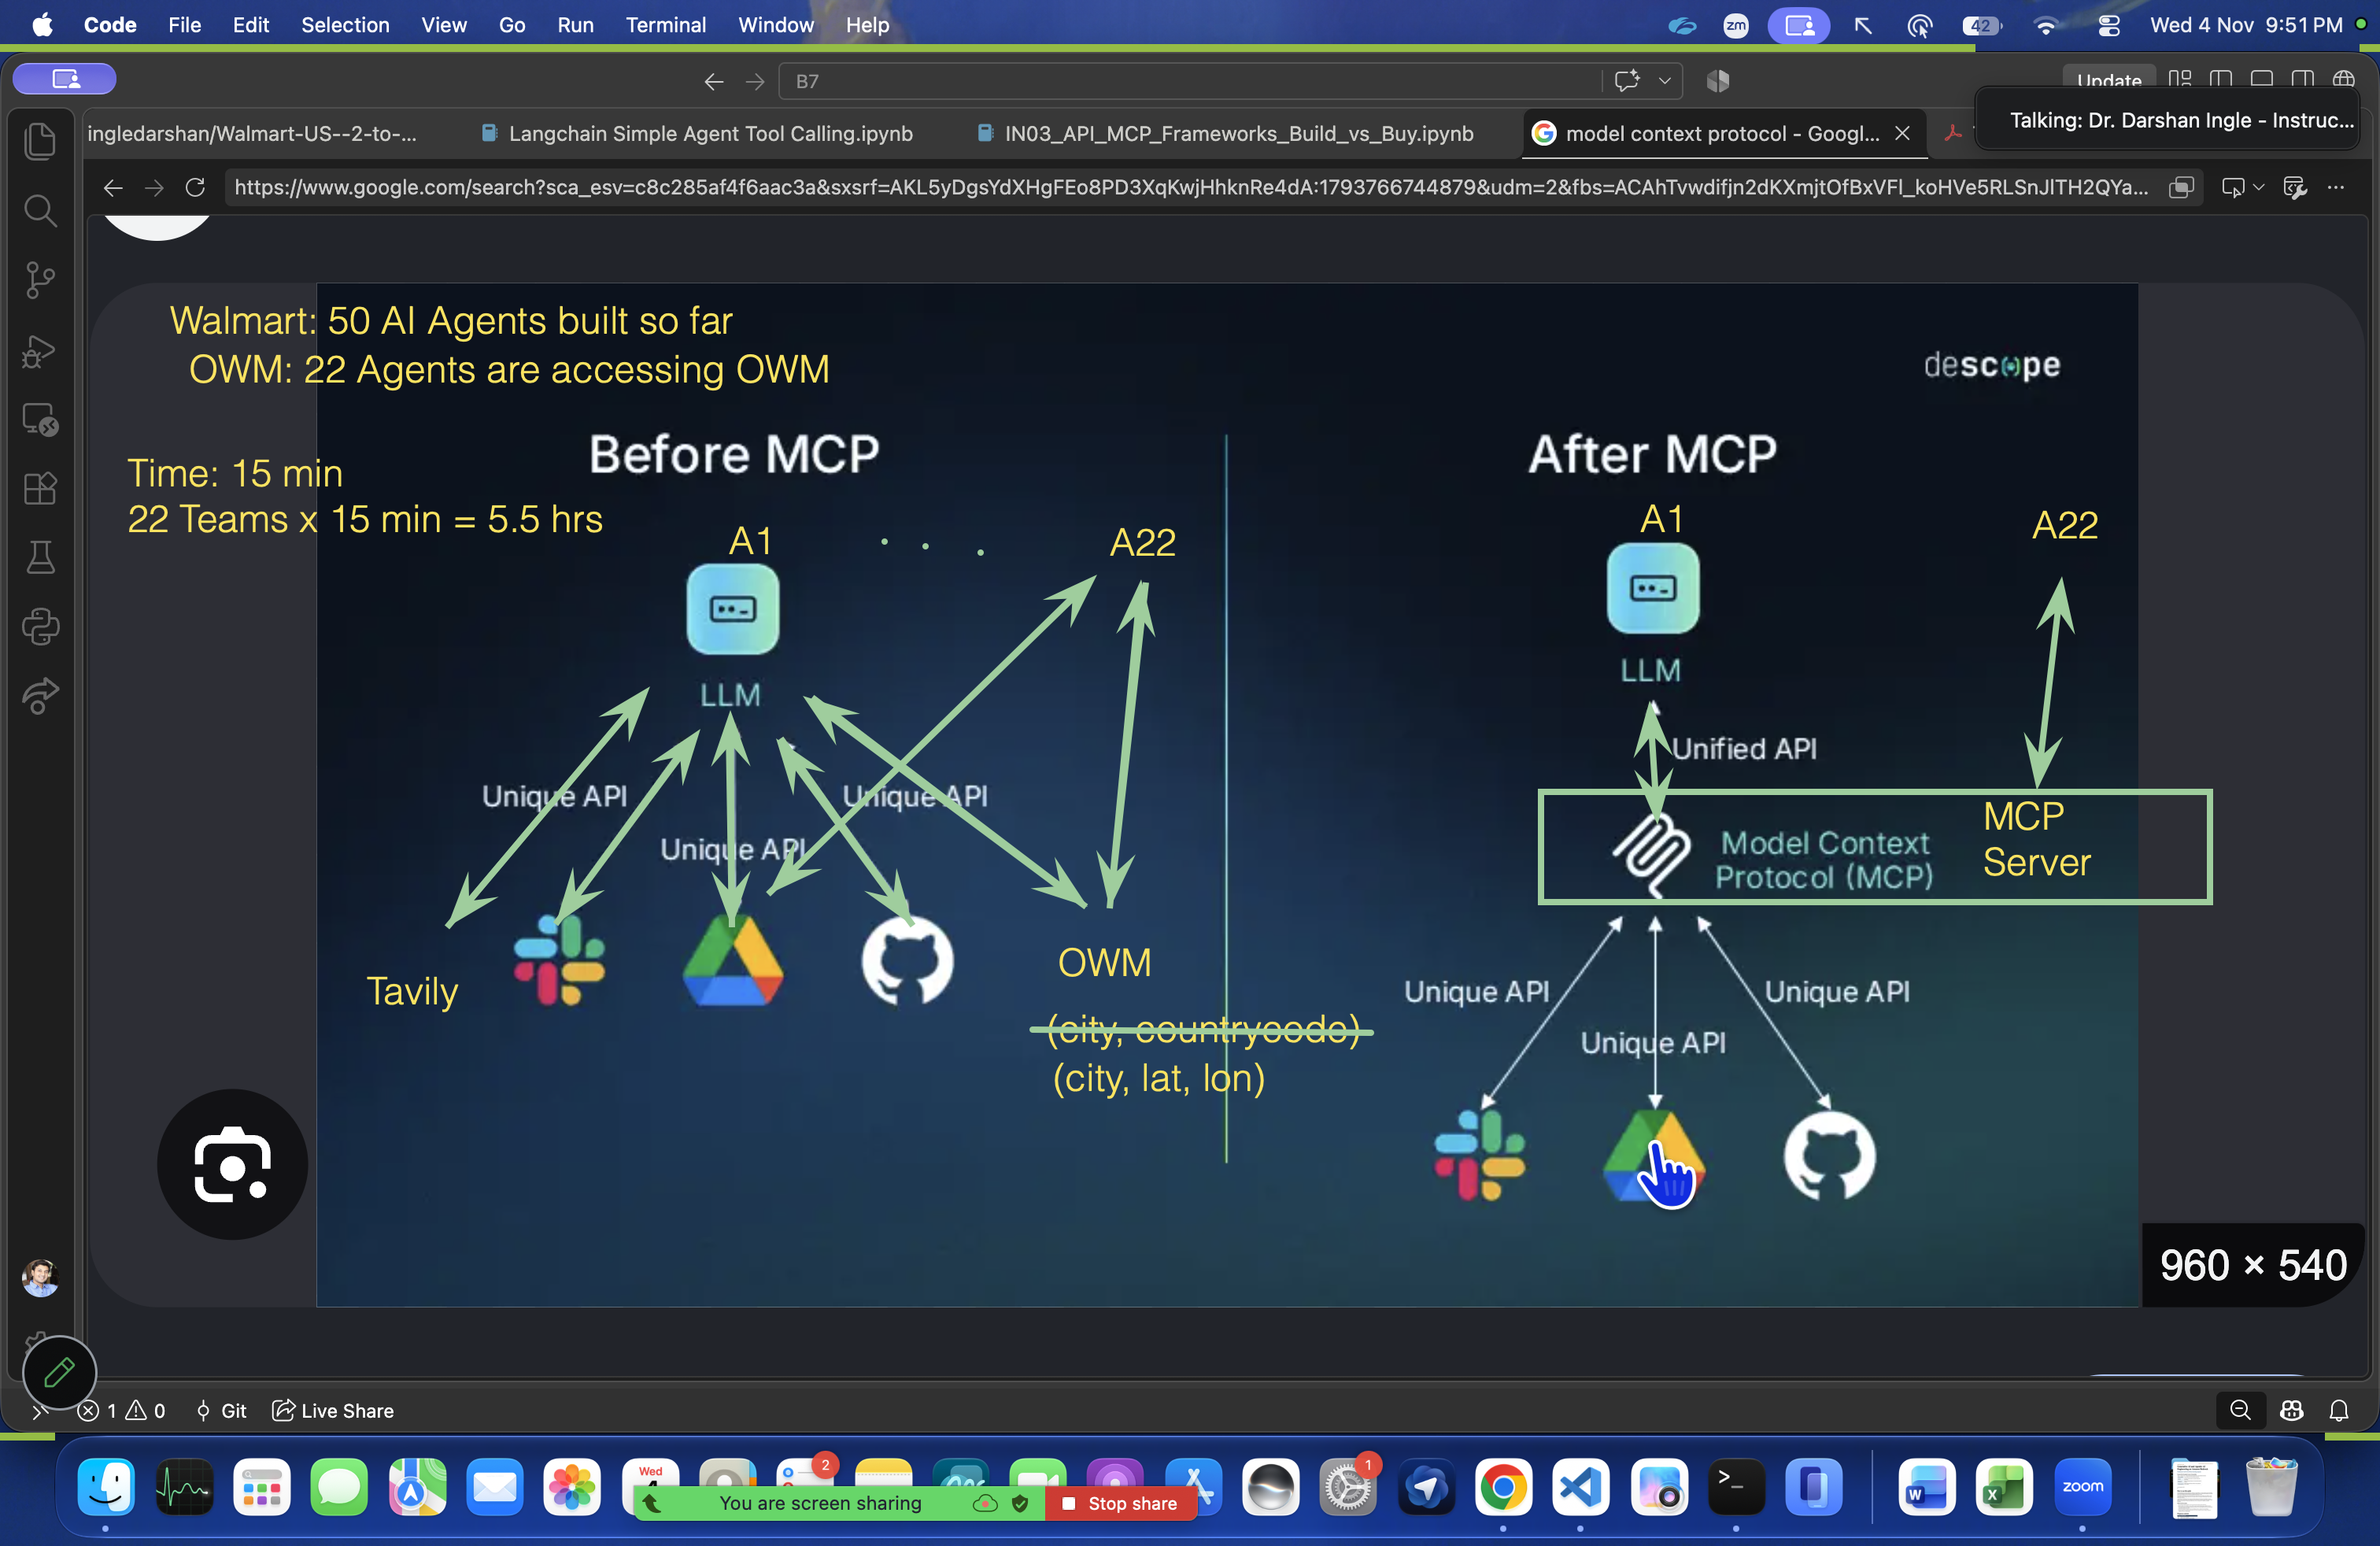

In [11]:
# What are MCP Host, Client and Server?

# MCP Host:
# The main AI application where the user interacts with the AI assistant. It manages the conversation, sends requests to the MCP Server, and receives responses.
# eg: Walmart AI Retail Assistant

# MCP Client:
# The connector inside the host that communicates using MCP protocol.
# eg: Component connecting the assistant to the weather MCP server

# MCP Server:
# Exposes tools and data to MCP clients.
# eg: Server offering get_store_weather

## MCP architecture

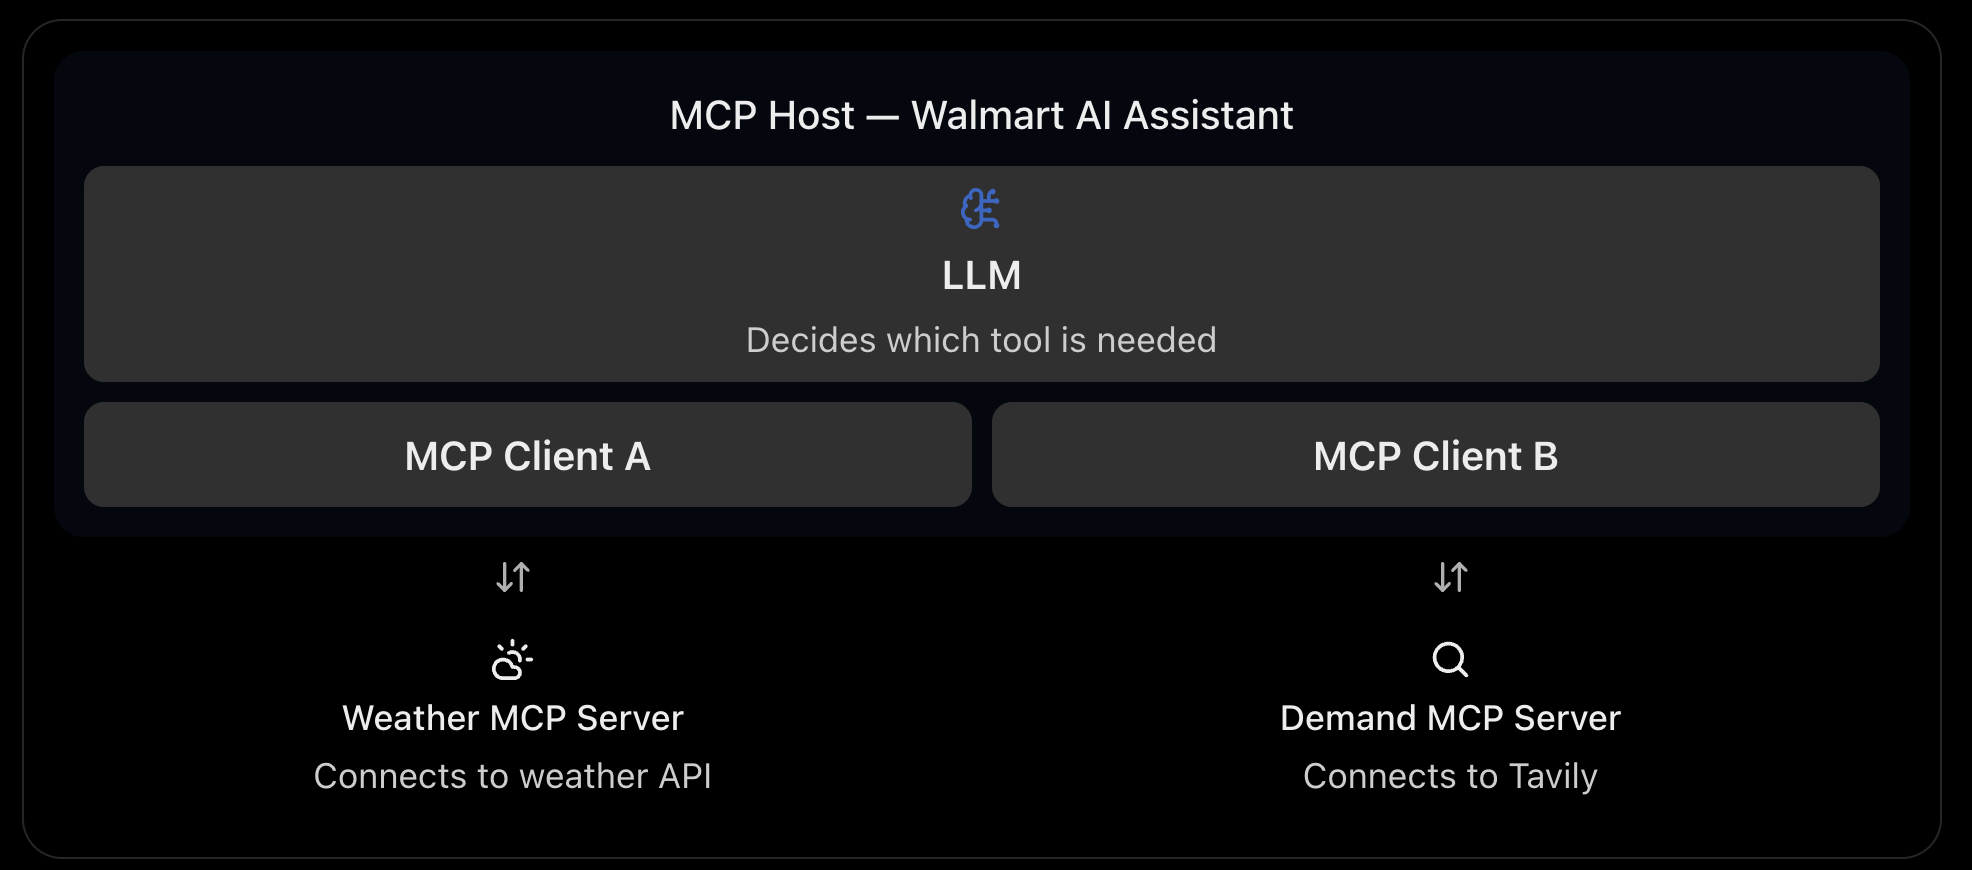

In [12]:
# One MCP host can contain multiple MCP clients, typically one for each server connection.

In [13]:
# How does MCP work step by step?
# Suppose the Walmart manager asks, "What should I stock today?"
# 1. Host: Receives the question.
# 2. Client: Connects to the MCP server and discovers available tools.
# 3. Server: Advertises tools such as get_store_weather.
# 4. LLM: Decides that weather information is required.
# 5. Client: Sends the tool request to the server.
# 6. Server: Calls the weather API and returns the result.
# 7. Host: Gives the result to the LLM, which prepares its recommendation.

| REST-style approach in our notebook              | MCP approach                                      |
| ------------------------------------------------ | ------------------------------------------------- |
| Tool schemas manually supplied to each agent     | Server advertises tool schemas                    |
| Custom Python tool dispatcher                    | Standard MCP tool invocation                      |
| Integration may be duplicated across agents      | One server can be reused by multiple applications |
| Changes may require updates to individual agents | Tool interface can be maintained centrally        |
| Simple for a few integrations                    | Useful for shared, growing tool ecosystems        |

In [14]:
# This cell sets up the FastMCP server and registers its tools.
# The main idea is that tool definitions live on the server side.
MCP_AVAILABLE = False

try:
    import inspect
     # from mcp.server.fastmcp import FastMCP
    from mcp.server.mcpserver import MCPServer

    # This helps async-friendly packages behave inside Jupyter.
    try:
        import nest_asyncio
        nest_asyncio.apply()
    except ImportError:
        pass

    # walmart_mcp = FastMCP(
    #     'walmart-store-ops',
    #     instructions=(
    #         'Walmart India Store Operations MCP Server. '
    #         'Exposes real-time weather intelligence and market demand signals '
    #         'for store management decisions at WMT stores across India.'
    #     ),
    # )

    walmart_mcp = MCPServer(
        'walmart-store-ops',
        instructions=(
            'Walmart India Store Operations MCP Server. '
            'Exposes real-time weather intelligence and market demand signals '
            'for store management decisions at WMT stores across India.'
        ),
    )

    @walmart_mcp.tool()
    def get_store_weather(city: str, country_code: str = 'IN') -> dict:
        """Get current weather at a Walmart India store location for demand planning."""
        return fetch_weather(city, country_code)

    @walmart_mcp.tool()
    def search_demand_trends(query: str, max_results: int = 3) -> dict:
        """Search live retail demand trends and market signals for store planning."""
        return fetch_demand_trends(query, max_results)

    @walmart_mcp.tool()
    def get_store_info(store_id: str) -> dict:
        """Retrieve operational metadata for a Walmart India store."""
        registry = {
            'WMT-2847': {'location': 'Bengaluru, Karnataka', 'format': 'Supercenter',
                         'departments': 32, 'daily_queries': 1200, 'region': 'South India'},
            'WMT-1023': {'location': 'Mumbai, Maharashtra',  'format': 'Supercenter',
                         'departments': 28, 'daily_queries': 1800, 'region': 'West India'},
            'WMT-0511': {'location': 'Delhi NCR',            'format': 'Supercenter',
                         'departments': 35, 'daily_queries': 2100, 'region': 'North India'},
            'WMT-3302': {'location': 'Hyderabad, Telangana', 'format': 'Neighborhood Market',
                         'departments': 18, 'daily_queries':  620, 'region': 'South India'},
        }
        return registry.get(store_id, {'error': f'Store {store_id} not found in registry'})

    def _annotation_to_json_type(annotation) -> str:
        # Convert Python type hints into simple JSON schema types.
        return {
            str: 'string',
            int: 'integer',
            float: 'number',
            bool: 'boolean',
            dict: 'object',
            list: 'array',
        }.get(annotation, 'string')

    def _build_mcp_tool_entry(func) -> dict:
        # Build a small machine-readable schema for each MCP tool.
        sig = inspect.signature(func)
        properties = {}
        required = []

        for param_name, param in sig.parameters.items():
            if param.kind not in (inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY):
                continue

            prop = {'type': _annotation_to_json_type(param.annotation)}
            if param.default is not inspect._empty:
                prop['default'] = param.default
            else:
                required.append(param_name)
            properties[param_name] = prop

        return {
            'name': func.__name__,
            'description': inspect.getdoc(func) or '',
            'inputSchema': {
                'type': 'object',
                'properties': properties,
                'required': required,
            },
            'handler': func,
        }

    # Keep the registered MCP tools in one place for easy lookup below.
    MCP_TOOL_REGISTRY = {
        tool['name']: tool
        for tool in [
            _build_mcp_tool_entry(get_store_weather),
            _build_mcp_tool_entry(search_demand_trends),
            _build_mcp_tool_entry(get_store_info),
        ]
    }

    def call_mcp_tool(name: str, args: dict) -> dict:
        # Run an MCP tool by name using the saved registry entry.
        return MCP_TOOL_REGISTRY[name]['handler'](**args)

    MCP_AVAILABLE = True
    print(f'FastMCP server created: {walmart_mcp.name}')
    print()
    print('Tools registered on the MCP server:')
    print('  - get_store_weather    (live data: OpenWeatherMap API)')
    print('  - search_demand_trends (live data: Tavily Search API)')
    print('  - get_store_info       (store registry -- note: 3 tools vs 2 for REST)')
    print()
    print('Key difference from REST: tool descriptions live here on the server,')
    print('not in the developer\'s agent code. Any MCP client discovers them automatically.')

except ImportError as e:
    print(f'mcp package not installed: {e}')
    print('Install: pip install mcp --break-system-packages')
    print()
    print('The REST section above is fully functional without this package.')
    print('FastMCP cells below will be skipped gracefully.')

FastMCP server created: walmart-store-ops

Tools registered on the MCP server:
  - get_store_weather    (live data: OpenWeatherMap API)
  - search_demand_trends (live data: Tavily Search API)
  - get_store_info       (store registry -- note: 3 tools vs 2 for REST)

Key difference from REST: tool descriptions live here on the server,
not in the developer's agent code. Any MCP client discovers them automatically.


In [15]:
# Now combine MCP tool schemas, MCP tool execution, and the LLM in one loop.
# This mirrors the REST agent flow, but the tool schema comes from the server side.
# Step 3: Full MCP Agent -- schema from server registry, tool execution from MCP server definitions

if MCP_AVAILABLE:
    def walmart_mcp_agent(query: str) -> dict:
        # Run a full MCP-style agent loop using the server-owned schema.
        start = time.time()

        openai_tools = [
            {
                'type': 'function',
                'function': {
                    'name':        t['name'],
                    'description': t['description'],
                    'parameters':  t['inputSchema'],
                },
            }
            for t in MCP_TOOL_REGISTRY.values()
        ]

        messages = [
            {
                'role': 'system',
                'content': (
                    f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                    'Tools are provided by the Walmart MCP server. '
                    'Use all relevant tools to give a complete, data-driven recommendation.'
                ),
            },
            {'role': 'user', 'content': query},
        ]

        tools_called = []
        total_in = total_out = 0
        final_answer = ''

        # Keep going until the model stops asking for tool calls.
        for _ in range(6):
            resp = client.chat.completions.create(
                model='gpt-4o', messages=messages, tools=openai_tools,
                tool_choice='auto', temperature=0, max_tokens=500,
            )
            total_in  += resp.usage.prompt_tokens
            total_out += resp.usage.completion_tokens
            msg = resp.choices[0].message

            if not msg.tool_calls:
                final_answer = msg.content.strip()
                break

            messages.append(msg)

            for tc in msg.tool_calls:
                args   = json.loads(tc.function.arguments)
                result = call_mcp_tool(tc.function.name, args)
                tools_called.append({'tool': tc.function.name, 'args': args})
                messages.append({
                    'role':         'tool',
                    'tool_call_id': tc.id,
                    'content':      json.dumps(result),
                })

        latency = time.time() - start
        cost    = (total_in * 2.50 + total_out * 10.00) / 1_000_000
        return {
            'answer':       final_answer,
            'tools_called': tools_called,
            'latency_sec':  round(latency, 2),
            'cost_usd':     round(cost, 6),
            'tokens_in':    total_in,
            'tokens_out':   total_out,
            'protocol':     'MCP',
        }

    mcp_result = walmart_mcp_agent(STORE_QUERY)

    print('Tools called via MCP protocol:')
    for t in mcp_result['tools_called']:
        print(f'  {t["tool"]}({json.dumps(t["args"])})')
    print()
    print('MCP Agent Answer (based on live data):')
    print('-' * 70)
    print(mcp_result['answer'])
    print('-' * 70)
    print(f'Latency : {mcp_result["latency_sec"]}s')
    print(f'Cost    : ${mcp_result["cost_usd"]}')
    print(f'Protocol: MCP (schema auto-discovered from FastMCP server)')

else:
    mcp_result = {**rest_result, 'protocol': 'MCP (fallback -- install mcp package)'}
    print('mcp package not installed. Showing REST result as reference.')
    print(f'Answer: {mcp_result["answer"][:300]}...')

[11/04/26 22:18:23] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=744612;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=301485;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

[11/04/26 22:18:32] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=67202;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=816148;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

Tools called via MCP protocol:
  get_store_weather({"city": "Bengaluru"})
  search_demand_trends({"query": "Bengaluru retail demand"})

MCP Agent Answer (based on live data):
----------------------------------------------------------------------
Based on today's weather conditions and current market demand signals in Bengaluru, here are three specific product categories you should prioritize stocking at WMT-2847:

1. **Rain Gear and Accessories**:
   - **Reason**: The current weather in Bengaluru is characterized by heavy intensity rain with a high humidity level of 88%. This makes rain gear such as umbrellas, raincoats, and waterproof footwear essential for customers. Stocking these items will cater to immediate needs driven by the weather conditions.

2. **Apparel**:
   - **Reason**: The retail demand trends indicate a strong leasing demand in Bengaluru's retail market, with a significant share in the Apparel sector. This suggests a growing consumer interest and purchasing power in c

## Section 3: Framework Selection -- LangChain vs LangGraph vs Python-only

Framework selection is a TCO (Total Cost of Ownership) decision, not a features decision.
Every framework adds capabilities and adds cost: dependency risk, debugging complexity, version lock, and team learning curve.

All three implementations below use the **same real live data** (OpenWeatherMap + Tavily).
The difference is in how each framework manages state, control flow, and observability.

In [16]:
# This version uses plain Python only: no tool framework, no graph, just direct calls.
# It is the simplest option, but the developer must control every step manually.
def python_only_agent(query: str) -> dict:
    # Python-only: full control, minimum abstraction.
    # Developer manually fetches data before the LLM call -- no dynamic tool calling.
    start = time.time()

    weather = fetch_weather(STORE_CITY)
    demand  = fetch_demand_trends(f'retail product demand {STORE_CITY} India', max_results=2)

    context = (
        f'Live weather for {STORE_CITY}: {json.dumps(weather)}. '
        f'Market demand signals: {demand["answer"][:400]}'
    )

    resp = client.chat.completions.create(
        model='gpt-4o-mini',
        messages=[
            {
                'role': 'system',
                'content': (
                    f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
                    f'Current live data: {context}'
                ),
            },
            {'role': 'user', 'content': query},
        ],
        temperature=0, max_tokens=400,
    )

    latency = time.time() - start
    ti, to  = resp.usage.prompt_tokens, resp.usage.completion_tokens
    return {
        'answer':      resp.choices[0].message.content.strip(),
        'latency_sec': round(latency, 2),
        'cost_usd':    round((ti * 0.15 + to * 0.60) / 1_000_000, 6),
        'framework':   'Python-only',
        'data_fetch':  'Manual pre-fetch (LLM cannot request more data dynamically)',
        'loc_approx':  30,
    }

py_result = python_only_agent(STORE_QUERY)
print('Python-only Agent Answer:')
print('-' * 60)
print(py_result['answer'][:450])
print('-' * 60)
print(f'Latency: {py_result["latency_sec"]}s | Framework: Python-only')
print(f'Note   : {py_result["data_fetch"]}')

[11/04/26 22:18:37] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=874747;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=753977;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

Python-only Agent Answer:
------------------------------------------------------------
Based on the current weather conditions in Bengaluru and the market demand signals, here are three specific product categories you should prioritize stocking today:

1. **Rain Gear and Umbrellas**:
   - **Reason**: The live weather data indicates "heavy intensity rain" with a temperature of 22.5°C and high humidity at 88%. This suggests that customers will be looking for rain protection items such as umbrellas, raincoats, and waterproof footwear.
------------------------------------------------------------
Latency: 4.5s | Framework: Python-only
Note   : Manual pre-fetch (LLM cannot request more data dynamically)


In [17]:
# %pip install langchain langchain-openai -q

In [18]:
# This version uses LangChain to manage tools and the agent loop for us.
# It reduces boilerplate, but adds another abstraction layer to learn and debug.
LC_AVAILABLE = False
lc_latency   = None

try:
    from langchain_openai import ChatOpenAI # LLM / Brain
    from langchain_core.prompts import ChatPromptTemplate # Prompt/Ears
    from langchain_core.tools import tool # Hands
    from langchain.agents import create_tool_calling_agent, AgentExecutor
    # create_tool_calling_agent - Combining LLM+Prompt+Tools
    # AgentExecutor - Running everything

    @tool
    def lc_get_weather(city: str) -> str:
        """Get real-time weather at a Walmart India store location for demand planning."""
        return json.dumps(fetch_weather(city))

    @tool
    def lc_search_trends(query: str) -> str:
        """Search for real-time retail demand trends and market signals using Tavily."""
        return json.dumps(fetch_demand_trends(query, max_results=2))

    lc_llm   = ChatOpenAI(model='gpt-4o-mini', temperature=0)
    lc_tools = [lc_get_weather, lc_search_trends]

    lc_prompt = ChatPromptTemplate.from_messages([
        ('system',
         f'You are an AI assistant for Walmart India store {STORE_ID} in {STORE_CITY}. '
         'Use tools to retrieve live data before making recommendations.'),
        ('human', '{input}'),
        ('placeholder', '{agent_scratchpad}'),
    ])

    lc_agent    = create_tool_calling_agent(lc_llm, lc_tools, lc_prompt)
    lc_executor = AgentExecutor(agent=lc_agent, tools=lc_tools, verbose=False, max_iterations=6)

    start       = time.time()
    lc_response = lc_executor.invoke({'input': STORE_QUERY})
    # lc_response = lc_executor.invoke({'input': "What is the current date and time in India?"})
    lc_latency  = time.time() - start

    print('LangChain Agent Answer (real tools via LCEL + AgentExecutor):')
    print('-' * 60)
    print(lc_response['output'][:450])
    print('-' * 60)
    print(f'Latency: {lc_latency:.2f}s | Framework: LangChain')
    LC_AVAILABLE = True

except ImportError as e:
    print(f'LangChain not installed: {e}')
    print('Install: pip install langchain langchain-openai --break-system-packages')

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[11/04/26 22:18:41] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=501025;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=683670;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

[11/04/26 22:18:46] INFO     HTTP Request: POST https://api.openai.com/v1/chat/completions          ]8;id=205245;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=125131;file:///opt/homebrew/lib/python3.11/site-packages/httpx/_client.py#1025\1025]8;;\
                             "HTTP/1.1 200 OK"                                                                     

LangChain Agent Answer (real tools via LCEL + AgentExecutor):
------------------------------------------------------------
Based on the current weather conditions in Bengaluru and the insights from market demand signals, here are three specific product categories you should prioritize stocking today:

1. **Rain Gear (Umbrellas, Raincoats, and Waterproof Bags)**
   - **Weather Support**: The current weather in Bengaluru indicates "heavy intensity rain" with a temperature of 22.5°C and high humidity (88%). This suggests that customers will be looking for protective gea
------------------------------------------------------------
Latency: 10.26s | Framework: LangChain


In [19]:
STORE_QUERY

"I am the store manager at WMT-2847 in Bengaluru. Based on today's actual weather conditions and current market demand signals, give me 3 specific product categories I should prioritise stocking today. For each category, explain why the live data supports this recommendation."